# Leiden community profiling, with mixed-use percentages

**Draft for team review.** It tests a candidate novel method and compares it with every model built so far.

**The idea.** A station often serves several kinds of passengers at once. A mall station, for example, has shoppers, staff arriving before opening and staff leaving at closing. So instead of giving each station one label, we:

1. Link every station-window to the **10 station-windows that behave most like it**, using only the 17 behaviour features. The metro map is not used.
2. Run **Leiden** on that network to find communities: groups with many strong links inside and few outside.
3. Give every station-window a **percentage mix**: the share of its link weight that points into each community.
4. Read **change over time** as a shift in that mix (for example EXPO during and after Expo 2020).

**Data.** The feature table is read straight from S3 (`curated/features/`, built by Athena).

**Comparison.** K-means, Ward, a Gaussian mixture model (GMM), spectral, ST-GRSC, BPGC and Adaptive BPGC are all refitted here on the same `X`, and all are scored the same way. DBSCAN is read from its labels file.

In [1]:
from pathlib import Path
import time
import warnings
import awswrangler as wr
import boto3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import igraph as ig
import leidenalg as la
from scipy.linalg import eigh
from scipy.spatial.distance import cdist, pdist, squareform
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REGION = "ap-south-1"
session = boto3.Session(region_name=REGION)
ACCOUNT_ID = session.client("sts").get_caller_identity()["Account"]
BUCKET = f"dubai-metro-profiling-{ACCOUNT_ID}"
FEATURES_S3 = f"s3://{BUCKET}/curated/features/"
UNSCALED_S3 = f"s3://{BUCKET}/curated/features_unscaled/"
EDGES_FILE = ROOT / "reference" / "edges.csv"       # station graph, needed only by the map-based methods
HAND_LABELS = ROOT / "results" / "hand_labels.csv"
LABELS_DIR = ROOT / "results" / "labels"
METRICS_DIR = ROOT / "results" / "metrics"
FIGURES = ROOT / "figures"
for folder in (LABELS_DIR, METRICS_DIR, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
K = 6                        # cluster count for the methods that need one (matches Ward and the team's k = 6)
KNN = 10                     # each station-window links to its 10 most similar station-windows
LOCAL_SCALE = 7              # per-row similarity scale = distance to the 7th nearest row (self-tuning)
RESOLUTIONS = [0.5, 0.75, 1.0, 1.25, 1.5]
STAB_REPEATS = 20            # station-grouped resamples
STAB_FRAC = 0.8              # keep 80% of physical stations per resample

SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948",
          "#6b6a66", "#00a3b4", "#a35c00", "#9c27b0"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.edgecolor": GRID, "axes.spines.top": False,
    "axes.spines.right": False, "figure.dpi": 130})
pd.set_option("display.width", 220, "display.max_columns", 40)

## 1. Read the feature table from S3

In [2]:
df = (wr.s3.read_parquet(FEATURES_S3, boto3_session=session)
        .sort_values(["location_id", "win"]).reset_index(drop=True))
unscaled = wr.s3.read_parquet(UNSCALED_S3, boto3_session=session)
print("read", len(df), "rows from", FEATURES_S3.replace(ACCOUNT_ID, "<account>"))
ID_COLUMNS = ["win", "location_id", "station", "timed_taps", "check_ins", "check_outs"]
FEATURE_COLUMNS = [c for c in df.columns if c not in ID_COLUMNS]
X = df[FEATURE_COLUMNS].to_numpy()
N = len(X)
STATIONS = df["location_id"].unique()
assert X.shape == (244, 17) and not np.isnan(X).any()
print("X:", X.shape, "| physical stations:", len(STATIONS))

read 244 rows from s3://dubai-metro-profiling-<account>/curated/features/
X: (244, 17) | physical stations: 53


## 2. Shared helpers

- `behaviour_graph`: the 10-nearest-neighbour similarity network. Similarity is `exp(-d² / (s_i · s_j))`, where `s_i` is row *i*'s distance to its 7th nearest row. Busy and quiet parts of the feature space are both handled fairly.
- `leiden`: Leiden community detection on that network.
- `community_mix`: the percentage mix for each row.
- `stability`: hide 20% of the stations, refit, and compare the remaining rows with the full fit using ARI (1 = identical groups, 0 = chance). Every method sees the same 20 resamples.
- `switches`: how often a station changes group between consecutive windows.

In [3]:
def behaviour_graph(x, k=KNN, local=LOCAL_SCALE):
    d = squareform(pdist(x))
    scale = np.sort(d, axis=1)[:, local]                    # column 0 is the row itself
    s = np.exp(-d**2 / np.outer(scale, scale))
    np.fill_diagonal(s, 0.0)
    keep = np.zeros_like(s)
    top = np.argsort(-s, axis=1)[:, :k]
    rows = np.arange(len(x))[:, None]
    keep[rows, top] = s[rows, top]
    return np.maximum(keep, keep.T)                         # symmetric: linked if either picks the other


def leiden(w, resolution, seed=SEED):
    i, j = np.nonzero(np.triu(w))
    g = ig.Graph(n=len(w), edges=list(zip(i.tolist(), j.tolist())))
    g.es["weight"] = w[i, j].tolist()
    part = la.find_partition(g, la.RBConfigurationVertexPartition, weights="weight",
                             resolution_parameter=resolution, seed=seed, n_iterations=-1)
    return np.array(part.membership)                        # community 0 is the largest


def community_mix(w, labels):
    k = labels.max() + 1
    mix = np.column_stack([w[:, labels == c].sum(axis=1) for c in range(k)])
    return mix / mix.sum(axis=1, keepdims=True)


def stability(fit, full_labels, repeats=STAB_REPEATS):
    rng = np.random.default_rng(SEED + 2026)                # identical resamples for every method
    scores = []
    for r in range(repeats):
        keep = rng.choice(STATIONS, size=int(np.ceil(STAB_FRAC * len(STATIONS))), replace=False)
        idx = np.flatnonzero(df["location_id"].isin(keep).to_numpy())
        scores.append(adjusted_rand_score(full_labels[idx], fit(idx, SEED + r)))
    return float(np.mean(scores)), float(np.std(scores))


def switches(labels):
    t = df[["location_id", "win"]].assign(c=labels).sort_values(["location_id", "win"])
    per_station = t.groupby("location_id")["c"].apply(lambda c: int((c.values[1:] != c.values[:-1]).sum()))
    return int((per_station > 0).sum()), int(per_station.sum())


def score(name, labels, stab=(np.nan, np.nan), note=""):
    labels = np.asarray(labels)
    m = labels != -1
    xl, ll = X[m], labels[m]
    groups = np.unique(ll)
    ok = 1 < len(groups) < len(ll)
    sse = sum(((xl[ll == c] - xl[ll == c].mean(axis=0)) ** 2).sum() for c in groups)
    changing, n_switches = switches(labels)
    return {"method": name, "clusters": len(groups), "noise": int((~m).sum()),
            "silhouette": silhouette_score(xl, ll) if ok else np.nan,
            "davies_bouldin": davies_bouldin_score(xl, ll) if ok else np.nan,
            "calinski_harabasz": calinski_harabasz_score(xl, ll) if ok else np.nan,
            "sse": sse, "stability_ari": stab[0], "stability_sd": stab[1],
            "stations_changing": changing, "switches": n_switches, "note": note}

## 3. Choose the Leiden resolution

Resolution controls the level of detail: lower values give fewer, bigger communities.

**Selection rule:** take the resolution with the **highest stability**, breaking ties with fewer communities. Silhouette is shown but is not used to choose. *Honesty note: this rule was written on 22 Nov 2026, after an exploratory run of the same five values. Report it that way.*

In [4]:
W = behaviour_graph(X)
print("network: rows", N, "| links", int(np.count_nonzero(np.triu(W))),
      "| mean links per row", round(np.count_nonzero(W) / N, 1))

sweep_rows, sweep_labels = [], {}
for res in RESOLUTIONS:
    labels = leiden(W, res)
    sweep_labels[res] = labels
    stab = stability(lambda idx, seed, res=res: leiden(behaviour_graph(X[idx]), res, seed=seed), labels)
    changing, n_switches = switches(labels)
    sweep_rows.append({"resolution": res, "communities": labels.max() + 1,
                       "smallest": int(np.bincount(labels).min()), "largest": int(np.bincount(labels).max()),
                       "silhouette": silhouette_score(X, labels),
                       "stability_ari": stab[0], "stability_sd": stab[1],
                       "stations_changing": changing, "switches": n_switches})
sweep = pd.DataFrame(sweep_rows)
sweep.round(3).to_csv(METRICS_DIR / "leiden_resolution_sweep.csv", index=False)

best = sweep.sort_values(["stability_ari", "communities"], ascending=[False, True]).iloc[0]
RESOLUTION = float(best["resolution"])
leiden_labels = sweep_labels[RESOLUTION]
print("chosen resolution:", RESOLUTION, "| communities:", leiden_labels.max() + 1)
sweep.round(3)

network: rows 244 | links 1434 | mean links per row 11.8


chosen resolution: 0.75 | communities: 8


,resolution,communities,smallest,largest,silhouette,stability_ari,stability_sd,stations_changing,switches
0,0.50,6,23,49,0.195,0.733,0.093,11,16
1,0.75,8,10,48,0.218,0.816,0.104,12,17
2,1.00,10,10,41,0.196,0.729,0.067,18,29
3,1.25,11,10,32,0.183,0.767,0.067,19,32
4,1.50,12,10,29,0.189,0.747,0.069,19,32


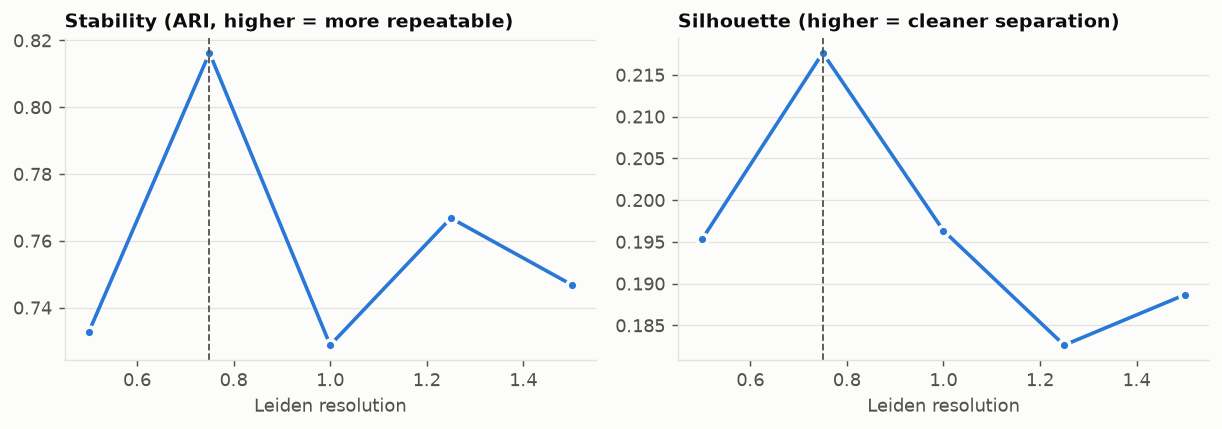

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
for ax, col, title in ((axes[0], "stability_ari", "Stability (ARI, higher = more repeatable)"),
                       (axes[1], "silhouette", "Silhouette (higher = cleaner separation)")):
    ax.plot(sweep["resolution"], sweep[col], color=SERIES[0], lw=2, marker="o", ms=6, mec=SURFACE, mew=2)
    ax.axvline(RESOLUTION, color=MUTED, ls="--", lw=1)
    ax.set_title(title, loc="left", fontsize=10.5, fontweight="bold")
    ax.set_xlabel("Leiden resolution")
    ax.grid(axis="y", color=GRID, lw=0.7)
fig.tight_layout()
fig.savefig(FIGURES / "leiden_resolution.png", dpi=200)

## 4. What each community looks like

The team names the communities. The code only shows their average behaviour (unscaled shares, in %) and the stations that sit in them most often.

In [6]:
df["community"] = leiden_labels
profile = unscaled.merge(df[["win", "location_id", "community"]], on=["win", "location_id"])
show = {"check_out_share_07_10": "arrive 07-10", "check_out_share_10_16": "arrive 10-16",
        "check_out_share_16_20": "arrive 16-20", "check_in_share_07_10": "leave 07-10",
        "check_in_share_16_20": "leave 16-20", "check_in_share_20_24": "leave 20-24",
        "weekend_share": "weekend"}
community_profile = (profile.groupby("community")[list(show)].mean() * 100).round(1).rename(columns=show)
community_profile.insert(0, "rows", profile.groupby("community").size())
community_profile.insert(1, "stations", profile.groupby("community")["station"].nunique())
members = (df.groupby("community")["station"]
             .apply(lambda s: ", ".join(f"{n} ({c})" for n, c in s.value_counts().head(6).items())))
community_profile["most frequent stations (windows)"] = members
community_profile.to_csv(METRICS_DIR / "leiden_community_profiles.csv")
community_profile

,rows,stations,arrive 07-10,arrive 10-16,arrive 16-20,leave 07-10,leave 16-20,leave 20-24,weekend,most frequent stations (windows)
community,,,,,,,,,,
0,48,13,27.3,26.9,25.3,13.3,41.9,14.9,20.7,"World Trade Centre (5), Emirates Towers (5), B..."
1,42,10,8.3,21.4,41.2,27.1,24.3,14.6,24.3,"Al Rigga (5), Union (5), BurJuman (5), ADCB (5..."
2,41,11,13.2,23.7,35.0,22.8,29.4,14.1,23.4,"centrepoint (5), max (5), Etisalat (5), Dubai ..."
3,39,10,42.0,24.7,16.4,6.8,54.6,13.8,18.8,"Emirates (5), GGICO (5), Equiti (5), Al Khail ..."
4,29,8,17.9,33.6,32.5,7.5,37.8,26.2,28.6,"City Centre Deira (5), Burj Khalifa/ Dubai Mal..."
5,21,5,9.9,29.0,37.5,17.3,29.1,22.4,28.0,"Baniyas Square (5), Gold Souq (5), Al Ghubaiba..."
6,14,8,15.6,22.0,28.5,14.4,37.6,12.4,29.6,"Danube (5), Al Jadaf (2), Dubai Investment Par..."
7,10,2,13.8,26.3,23.0,15.1,26.4,20.6,24.2,"Airport Terminal 3 (5), Airport Terminal 1 (5)"


## 5. The percentage mix

For each station-window: the share of its link weight that points into each community. A station whose 10 nearest look-alikes all sit in one community is **pure** (close to 100%). A station whose look-alikes are split is **mixed**.

In [7]:
mix = community_mix(W, leiden_labels)
n_comm = mix.shape[1]
mix_df = pd.DataFrame(mix, columns=[f"C{c}" for c in range(n_comm)])
mix_df.insert(0, "station", df["station"]); mix_df.insert(0, "location_id", df["location_id"]); mix_df.insert(0, "win", df["win"])
mix_df["top_share"] = mix.max(axis=1)
mix_df.round(3).to_csv(METRICS_DIR / "leiden_mix.csv", index=False)

print("rows whose largest share is below 70% (clearly mixed):", int((mix_df.top_share < 0.7).sum()), "of", N)
EXAMPLES = ["Burj Khalifa/ Dubai Mall", "Mall of the Emirates", "Ibn Battuta", "City Centre Deira",
            "Financial Centre", "Business Bay", "Union", "Airport Terminal 3", "EXPO"]
avg_mix = mix_df[mix_df.station.isin(EXAMPLES)].groupby("station")[[f"C{c}" for c in range(n_comm)]].mean()
avg_mix = avg_mix.loc[[s for s in EXAMPLES if s in avg_mix.index]]
(avg_mix * 100).round(0).astype(int)

rows whose largest share is below 70% (clearly mixed): 25 of 244


,C0,C1,C2,C3,C4,C5,C6,C7
station,,,,,,,,
Burj Khalifa/ Dubai Mall,1,0,0,0,99,0,0,0
Mall of the Emirates,0,3,0,0,42,55,0,0
Ibn Battuta,1,1,3,0,38,57,0,0
City Centre Deira,1,0,0,0,90,9,0,0
Financial Centre,76,0,19,0,0,0,5,0
Business Bay,80,0,0,20,0,0,0,0
Union,0,98,0,0,0,2,0,0
Airport Terminal 3,1,0,0,2,0,0,0,97
EXPO,24,0,0,24,52,0,0,0


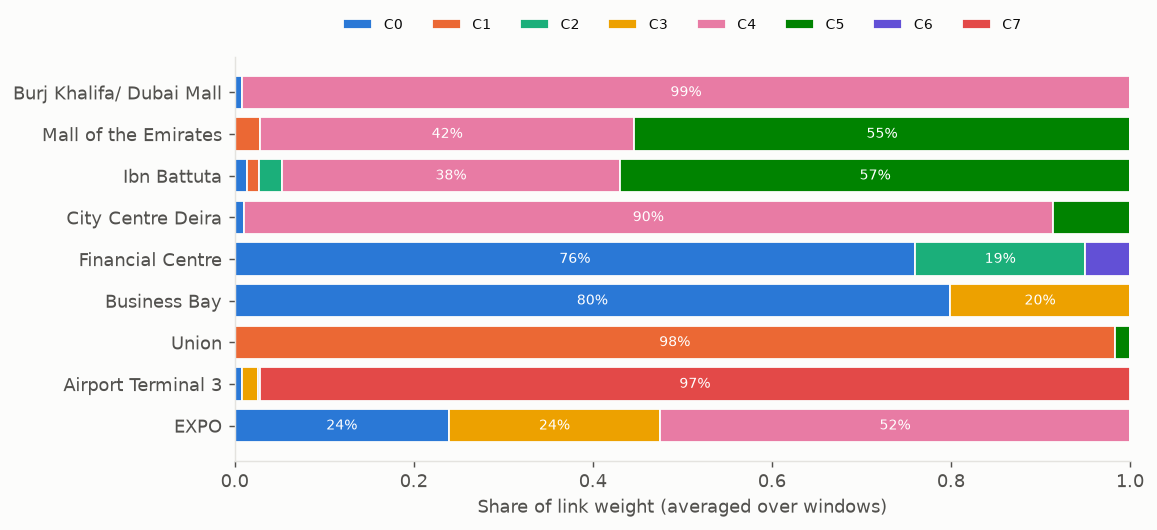

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.2))
left = np.zeros(len(avg_mix))
for c in range(n_comm):
    vals = avg_mix[f"C{c}"].to_numpy()
    ax.barh(avg_mix.index, vals, left=left, color=SERIES[c % len(SERIES)], edgecolor=SURFACE, lw=1, label=f"C{c}")
    for y, (l, v) in enumerate(zip(left, vals)):
        if v >= 0.12:
            ax.text(l + v / 2, y, f"{v:.0%}", ha="center", va="center", color="white", fontsize=8)
    left += vals
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("Share of link weight (averaged over windows)")
ax.legend(ncol=n_comm, frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, 1.13))
fig.tight_layout()
fig.savefig(FIGURES / "leiden_station_mix.png", dpi=200)

In [9]:
print("EXPO, window by window")
expo = mix_df[mix_df.station == "EXPO"].set_index("win")[[f"C{c}" for c in range(n_comm)]]
(expo * 100).round(0).astype(int)

EXPO, window by window


,C0,C1,C2,C3,C4,C5,C6,C7
win,,,,,,,,
W21/22,0,0,0,0,100,0,0,0
W24/25,48,0,0,47,5,0,0,0


## 6. Save Leiden labels in the shared format

The core columns follow the shared contract. `resolution` and `top_share` are extra columns.

In [10]:
leiden_out = df[["win", "location_id", "station"]].copy()
leiden_out["method"] = "leiden"
leiden_out["k"] = int(n_comm)
leiden_out["alpha"] = np.nan
leiden_out["cluster"] = leiden_labels
leiden_out["resolution"] = RESOLUTION
leiden_out["top_share"] = mix.max(axis=1)
leiden_out.to_parquet(LABELS_DIR / "leiden.parquet", index=False)
leiden_out.head()

,win,location_id,station,method,k,alpha,cluster,resolution,top_share
0,W17/18,128,centrepoint,leiden,8,NaN,2,0.75,1.000000
1,W18/19,128,centrepoint,leiden,8,NaN,2,0.75,0.943448
2,W19/20,128,centrepoint,leiden,8,NaN,2,0.75,1.000000
3,W21/22,128,centrepoint,leiden,8,NaN,2,0.75,0.877969
4,W24/25,128,centrepoint,leiden,8,NaN,2,0.75,1.000000


## 7. GMM: the closest existing alternative

A Gaussian mixture model also gives each row percentages (the Nanjing station study used one). It assumes every group is an oval-shaped cloud. Leiden follows the actual similarity links, so it makes no shape assumption. Diagonal covariance is used because 244 rows are too few for full 17×17 covariances.

In [11]:
gmm = GaussianMixture(n_components=K, covariance_type="diag", n_init=10, random_state=SEED).fit(X)
gmm_labels = gmm.predict(X)
gmm_prob = gmm.predict_proba(X)
print("GMM rows with largest probability below 70%:", int((gmm_prob.max(axis=1) < 0.7).sum()), "of", N)
print("Leiden rows with largest share below 70%:   ", int((mix.max(axis=1) < 0.7).sum()), "of", N)
gmm_mix = pd.DataFrame(gmm_prob, columns=[f"G{c}" for c in range(K)]).assign(station=df["station"])
(gmm_mix[gmm_mix.station.isin(EXAMPLES)].groupby("station").mean() * 100).round(0).astype(int)

GMM rows with largest probability below 70%: 0 of 244
Leiden rows with largest share below 70%:    25 of 244


,G0,G1,G2,G3,G4,G5
station,,,,,,
Airport Terminal 3,0,0,0,100,0,0
Burj Khalifa/ Dubai Mall,0,0,100,0,0,0
Business Bay,0,0,0,0,100,0
City Centre Deira,0,0,100,0,0,0
EXPO,0,50,50,0,0,0
Financial Centre,0,75,0,25,0,0
Ibn Battuta,0,0,80,0,0,20
Mall of the Emirates,0,0,100,0,0,0
Union,0,0,0,0,0,100


## 8. Re-fit every model on the same data

Each method uses the settings from its own notebook or teammate branch:

| Method | Settings |
|---|---|
| K-means | k = 6, k-means++, 50 restarts |
| Ward | k = 6 |
| Spectral | global RBF (σ = median distance), k = 6 |
| ST-GRSC | α = 0.98, spatial + temporal links, mass-normalised, k = 6 (Aryan's branch) |
| BPGC | λ = 1.0, spatial links (Aryan's branch) |
| Adaptive BPGC | λ = 4.0, adaptive spatial weights, 7th-neighbour scale (Aryan's branch) |

These are **re-implementations**, so small differences from the teammates' own notebooks are expected. The map-based methods are skipped if `reference/edges.csv` is missing.

In [12]:
def rbf_global(x):
    s = np.exp(-squareform(pdist(x, "sqeuclidean")) / (2 * np.median(pdist(x)) ** 2))
    np.fill_diagonal(s, 0.0)
    return s

def spectral_labels(w, k=K, seed=SEED):
    d = w.sum(axis=1)
    vec = eigh(np.eye(len(w)) - w / np.sqrt(np.outer(d, d)))[1][:, :k]
    vec /= np.maximum(np.linalg.norm(vec, axis=1, keepdims=True), 1e-12)
    return KMeans(k, n_init=50, random_state=seed).fit_predict(vec)

mass = lambda m: m / m.sum()

HAVE_EDGES = EDGES_FILE.exists()
if HAVE_EDGES:
    edges = pd.read_csv(EDGES_FILE)
    edge_keys = [((e.src_win, int(e.src_location_id)), (e.dst_win, int(e.dst_location_id)), e.kind, float(e.weight))
                 for e in edges.itertuples()]
    SPATIAL_MEAN = edges.loc[edges.kind == "spatial", "weight"].mean()
else:
    print("reference/edges.csv not found: ST-GRSC, BPGC and Adaptive BPGC are skipped")

def graph_for(idx):
    pos = {(w, int(l)): i for i, (w, l) in enumerate(zip(df["win"].iloc[idx], df["location_id"].iloc[idx]))}
    n = len(idx); a_sp = np.zeros((n, n)); a_te = np.zeros((n, n))
    for a, b, kind, wt in edge_keys:
        if a in pos and b in pos:
            m = a_sp if kind == "spatial" else a_te
            m[pos[a], pos[b]] = m[pos[b], pos[a]] = wt
    return a_sp, a_te

def fit_spectral(idx, seed):
    return spectral_labels(mass(rbf_global(X[idx])), seed=seed)

def fit_stgrsc(idx, seed, alpha=0.98):
    a_sp, a_te = graph_for(idx)
    w = alpha * mass(rbf_global(X[idx])) + (1 - alpha) * (mass(a_sp) + mass(a_te)) / 2
    np.fill_diagonal(w, 0.0)
    return spectral_labels(w, seed=seed)

In [13]:
# BPGC and Adaptive BPGC: ported from Aryan's notebooks (feature/bpgc-clustering, feature/adaptive-bpgc)
def bp_fit(x, pairs, weights, k=K, lam=1.0, seed=SEED, restarts=20, max_iter=60, inner_sweeps=12):
    n = len(x)
    nbr_idx = [[] for _ in range(n)]; nbr_w = [[] for _ in range(n)]
    for (i, j), w in zip(pairs, weights):
        nbr_idx[i].append(j); nbr_w[i].append(w); nbr_idx[j].append(i); nbr_w[j].append(w)
    nbr_idx = [np.asarray(v, dtype=int) for v in nbr_idx]; nbr_w = [np.asarray(v, dtype=float) for v in nbr_w]
    strength = np.array([v.sum() for v in nbr_w])
    scale = max(KMeans(k, n_init=10, random_state=seed).fit(x).inertia_ / n, 1e-10)
    best = None
    for restart in range(restarts):
        km = KMeans(k, n_init=1, random_state=seed + restart).fit(x)
        labels, centers = km.labels_.copy(), km.cluster_centers_.copy()
        for it in range(max_iter):
            old = labels.copy(); D = cdist(x, centers, "sqeuclidean")
            for sweep_no in range(inner_sweeps):
                changed = 0
                for i in np.random.default_rng(seed + restart * 100003 + it * 101 + sweep_no).permutation(n):
                    cost = D[i].copy()
                    if lam > 0 and len(nbr_idx[i]):
                        cost += lam * scale * (strength[i] - np.bincount(labels[nbr_idx[i]], weights=nbr_w[i], minlength=k))
                    c = int(np.argmin(cost))
                    if c != labels[i]:
                        labels[i] = c; changed += 1
                if changed == 0: break
            if np.any(np.bincount(labels, minlength=k) == 0): break
            centers = np.vstack([x[labels == c].mean(axis=0) for c in range(k)])
            if np.array_equal(labels, old): break
        if np.any(np.bincount(labels, minlength=k) == 0): continue
        fit_part = cdist(x, centers, "sqeuclidean")[np.arange(n), labels].sum()
        obj = fit_part + lam * scale * weights[labels[pairs[:, 0]] != labels[pairs[:, 1]]].sum()
        if best is None or obj < best[0]:
            best = (obj, labels.copy())
    return best[1]

def adaptive_weights(x, pairs, base, n_neighbors=7):
    scales = np.maximum(NearestNeighbors(n_neighbors=n_neighbors).fit(x).kneighbors()[0][:, -1], np.finfo(float).eps)
    l, r = pairs.T
    logw = np.log(base) - ((x[l] - x[r]) ** 2).sum(axis=1) / (scales[l] * scales[r])
    w = np.exp(logw - logw.max())
    return w * (base.sum() / w.sum())

def spatial_pairs(idx):
    a_sp, _ = graph_for(idx)
    pairs = np.argwhere(np.triu(a_sp) > 0)
    return pairs, a_sp[pairs[:, 0], pairs[:, 1]] / SPATIAL_MEAN

def fit_bpgc(idx, seed, restarts=10):
    pairs, w = spatial_pairs(idx)
    return bp_fit(X[idx], pairs, w, lam=1.0, seed=seed, restarts=restarts)

def fit_abpgc(idx, seed, restarts=10):
    pairs, w = spatial_pairs(idx)
    return bp_fit(X[idx], pairs, adaptive_weights(X[idx], pairs, w), lam=4.0, seed=seed, restarts=restarts)

In [14]:
ALL = np.arange(N)
fitters = {
    "K-means (k=6)": lambda idx, seed: KMeans(K, init="k-means++", n_init=50, random_state=seed).fit_predict(X[idx]),
    "Ward (k=6)": lambda idx, seed: AgglomerativeClustering(K, linkage="ward").fit_predict(X[idx]),
    "GMM (k=6, diag)": lambda idx, seed: GaussianMixture(K, covariance_type="diag", n_init=10, random_state=seed).fit(X[idx]).predict(X[idx]),
    "Spectral (k=6)": fit_spectral,
}
if HAVE_EDGES:
    fitters["ST-GRSC (a=0.98)"] = fit_stgrsc
    fitters["BPGC (lambda=1)"] = fit_bpgc
    fitters["Adaptive BPGC (lambda=4)"] = fit_abpgc

rows, method_labels = [], {}
for name, fit in fitters.items():
    t0 = time.time()
    full = fit(ALL, SEED) if "BPGC" not in name else fit(ALL, SEED, restarts=20)
    method_labels[name] = full
    rows.append(score(name, full, stability(fit, full)))
    print(f"{name:28s} done in {time.time() - t0:5.1f}s")

leiden_name = f"Leiden + mix (res={RESOLUTION:g})"
method_labels[leiden_name] = leiden_labels
rows.append(score(leiden_name, leiden_labels,
                  stability(lambda idx, seed: leiden(behaviour_graph(X[idx]), RESOLUTION, seed=seed), leiden_labels),
                  note="proposed"))

db_file = LABELS_DIR / "dbscan.parquet"
if db_file.exists():
    db = df[["win", "location_id"]].merge(pd.read_parquet(db_file)[["win", "location_id", "cluster"]],
                                          on=["win", "location_id"], how="left")
    if db["cluster"].notna().all():
        method_labels["DBSCAN (labels file)"] = db["cluster"].astype(int).to_numpy()
        rows.append(score("DBSCAN (labels file)", method_labels["DBSCAN (labels file)"],
                          note="noise excluded from scores; not refitted, see 05_dbscan for its stability"))

K-means (k=6)                done in   2.4s
Ward (k=6)                   done in   0.2s


GMM (k=6, diag)              done in   1.2s


Spectral (k=6)               done in   2.7s


ST-GRSC (a=0.98)             done in   2.6s


BPGC (lambda=1)              done in   4.4s


Adaptive BPGC (lambda=4)     done in   3.9s


## 9. The comparison

The first five score columns are the class metrics:

| Metric | Better when |
|---|---|
| Silhouette | higher |
| Davies–Bouldin | lower |
| Calinski–Harabasz | higher |
| SSE | lower (compare only at the same cluster count) |
| Stability ARI | higher |

`stations_changing` and `switches` describe steadiness over time. Methods that use temporal links push these down on purpose, so read them with that in mind.

In [15]:
comparison = pd.DataFrame(rows)
comparison.round(4).to_csv(METRICS_DIR / "all_methods_comparison.csv", index=False)
comparison.round(3)

,method,clusters,noise,silhouette,davies_bouldin,calinski_harabasz,sse,stability_ari,stability_sd,stations_changing,switches,note
0,K-means (k=6),6,0,0.270,1.313,90.859,1426.014,0.932,0.038,16,27,
1,Ward (k=6),6,0,0.279,1.315,81.788,1525.994,0.752,0.123,8,10,
2,"GMM (k=6, diag)",6,0,0.197,1.522,85.368,1484.907,0.750,0.085,10,17,
3,Spectral (k=6),6,0,0.252,1.479,77.592,1577.137,0.715,0.137,25,44,
4,ST-GRSC (a=0.98),6,0,0.230,1.511,72.603,1642.593,0.696,0.153,26,46,
5,BPGC (lambda=1),6,0,0.242,1.332,82.026,1523.192,0.819,0.097,20,31,
6,Adaptive BPGC (lambda=4),6,0,0.232,1.404,78.676,1563.603,0.759,0.090,23,39,
7,Leiden + mix (res=0.75),8,0,0.218,1.345,72.237,1319.920,0.816,0.104,12,17,proposed
8,DBSCAN (labels file),2,33,0.281,0.867,19.255,2896.477,NaN,NaN,11,15,"noise excluded from scores; not refitted, see ..."


In [16]:
print("Agreement between methods (ARI on all 244 rows; 1 = identical grouping)")
names = [n for n in method_labels if not n.startswith("DBSCAN")]
agree = pd.DataFrame([[adjusted_rand_score(method_labels[a], method_labels[b]) for b in names] for a in names],
                     index=names, columns=names)
agree.round(2)

Agreement between methods (ARI on all 244 rows; 1 = identical grouping)


,K-means (k=6),Ward (k=6),"GMM (k=6, diag)",Spectral (k=6),ST-GRSC (a=0.98),BPGC (lambda=1),Adaptive BPGC (lambda=4),Leiden + mix (res=0.75)
K-means (k=6),1.00,0.66,0.72,0.67,0.63,0.79,0.78,0.54
Ward (k=6),0.66,1.00,0.59,0.50,0.51,0.69,0.66,0.69
"GMM (k=6, diag)",0.72,0.59,1.00,0.50,0.51,0.58,0.58,0.74
Spectral (k=6),0.67,0.50,0.50,1.00,0.82,0.57,0.57,0.43
ST-GRSC (a=0.98),0.63,0.51,0.51,0.82,1.00,0.59,0.58,0.45
BPGC (lambda=1),0.79,0.69,0.58,0.57,0.59,1.00,0.90,0.53
Adaptive BPGC (lambda=4),0.78,0.66,0.58,0.57,0.58,0.90,1.00,0.51
Leiden + mix (res=0.75),0.54,0.69,0.74,0.43,0.45,0.53,0.51,1.00


## 10. The 12 validation stations: where Leiden puts them

In [17]:
hand = pd.read_csv(HAND_LABELS)
check = df[["win", "location_id", "station", "community"]].merge(hand[["location_id", "expected_type"]], on="location_id")
check = check.merge(mix_df[["win", "location_id", "top_share"]], on=["win", "location_id"])
per_station = (check.groupby(["station", "expected_type"])
                    .agg(windows=("community", "size"),
                         communities=("community", lambda s: "/".join(str(v) for v in s)),
                         mean_top_share=("top_share", "mean"))
                    .reset_index().sort_values("expected_type"))
per_station["mean_top_share"] = (per_station["mean_top_share"] * 100).round(0).astype(int)
per_station.to_csv(METRICS_DIR / "leiden_vs_hand_labels.csv", index=False)
per_station

,station,expected_type,windows,communities,mean_top_share
0,Airport Terminal 3,Airport,5,7/7/7/7/7,97
5,Dubai Healthcare City,Business,5,3/3/3/3/3,100
7,Financial Centre,Business,5,0/0/0/2/0,76
10,Oud Metha,Education,5,4/4/4/4/4,84
2,Al Rigga,Mixed,5,1/1/1/1/1,99
4,DMCC,Mixed,5,0/0/0/0/0,96
11,Stadium,Residential,5,1/1/1/1/1,93
6,EXPO,Shopping and leisure,2,4/3,74
8,Ibn Battuta,Shopping and leisure,5,5/5/5/4/4,93
9,Mall of the Emirates,Shopping and leisure,5,4/4/5/5/5,74
